In [13]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
df = pd.read_csv('train.csv', usecols=['Age', 'Fare', 'Survived'])

In [15]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [16]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [17]:
df.isnull().mean()*100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [18]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [20]:
X_train

,Age,Fare
30,40.0,27.7208
10,4.0,16.7000
873,47.0,9.0000
182,9.0,31.3875
876,20.0,9.8458
...,...,...
534,30.0,8.6625
584,NaN,8.7125
493,71.0,49.5042
527,NaN,221.7792


In [26]:
# We create this copy so we can fill in the missing values without altering or losing your original data.
X_train['Age_imputed'] = X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [27]:
X_train.head()

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0


In [28]:
X_test.tail()

,Age,Fare,Age_imputed
89,24.0,8.0500,24.0
80,22.0,9.0000,22.0
846,NaN,69.5500,NaN
870,26.0,7.8958,26.0
251,29.0,10.4625,29.0


dataframe_name[ dataframe_name['column_name'].condition() ]

dataframe_name: Your whole Excel sheet.

['column_name'].condition(): Clicking the drop-down arrow on that column and picking a rule (like choosing "Blanks" or "> 30").

[ ... ] (The brackets): Applying that filter so it hides the rest of the sheet and only shows the matching rows.

In [32]:
X_train['Age_imputed'] [X_train['Age_imputed'].isnull()]  


77    NaN
868   NaN
334   NaN
295   NaN
792   NaN
       ..
674   NaN
466   NaN
584   NaN
527   NaN
168   NaN
Name: Age_imputed, Length: 148, dtype: float64

In [34]:
X_train['Age'].isnull().sum()

np.int64(148)

dropna(): Takes your Age column and drops (removes) all the empty (NaN) values, leaving behind a clean list of only real, valid ages..
sample(...): From that clean list of real ages, it randomly picks values. How many does it pick? Exactly the number of values that are missing (it counts the blanks to match them).\
.values: Turns those randomly picked ages into a simple, clean list of numbers so they are ready to be plugged into your missing spots.

So, in short: Drop the blanks values and  Randomly pick real ages to match the number of missing spots and Convert them to a plain list of values!

In [36]:
X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values # .sample() means "randomly pick items."

array([26.  , 29.  , 33.  , 16.  , 43.  , 22.  ,  4.  ,  5.  , 19.  ,
       25.  , 49.  , 22.  , 20.  , 29.  , 44.  , 21.  , 24.  , 41.  ,
       30.5 , 39.  , 29.  , 18.  , 17.  , 29.  , 21.  , 42.  , 25.  ,
       19.  , 16.  , 47.  , 42.  , 36.  , 43.  , 30.  , 14.  , 27.  ,
       11.  , 39.  , 28.  , 25.  , 29.  , 38.  , 40.  , 24.  , 19.  ,
       30.  , 23.  , 19.  , 17.  , 45.  ,  4.  ,  0.42,  9.  , 23.  ,
       27.  , 27.  , 36.  , 14.  , 38.  , 50.  , 24.  , 16.  , 16.  ,
       30.  , 22.  , 30.  , 36.  , 25.  , 24.  , 26.  , 34.  ,  4.  ,
        5.  , 26.  , 36.  , 28.  , 23.  , 32.  , 20.  , 58.  , 29.  ,
       39.  , 22.  , 34.  , 37.  , 28.  , 20.  , 38.  , 19.  , 31.  ,
       57.  , 21.  , 36.  , 65.  , 24.  , 58.  , 40.  , 56.  , 58.  ,
       34.  , 21.  , 35.  , 34.  , 17.  , 16.  ,  9.  , 27.  , 19.  ,
        1.  , 19.  , 23.  ,  9.  , 39.  ,  3.  , 12.  , 28.  , 45.  ,
       47.  , 24.  , 32.  , 35.  , 16.  , 16.  , 19.  , 14.  , 48.  ,
       24.  , 30.  ,

In [42]:
# For Training Data
X_train.loc[X_train['Age_imputed'].isnull(), 'Age_imputed'] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

# For Testing Data (Fixed to use X_test references!)
X_test.loc[X_test['Age_imputed'].isnull(), 'Age_imputed'] = X_train['Age'].dropna().sample(X_test['Age'].isnull().sum()).values

In [43]:
X_train # here you can see in age_imputed NaN value in Age is replaced by random value in Age_imputed

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,25.0
493,71.0,49.5042,71.0
527,NaN,221.7792,25.0


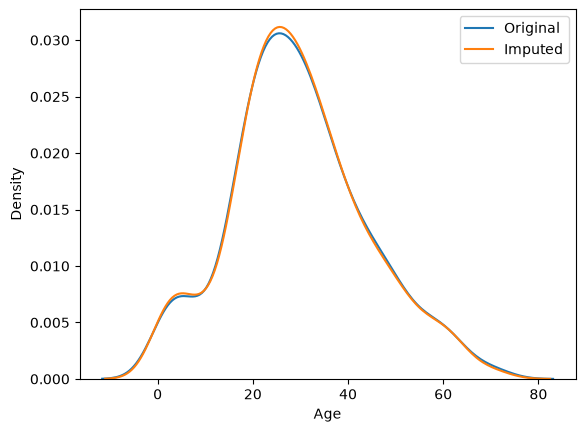

In [49]:
sns.kdeplot(X_train['Age'], label='Original')
sns.kdeplot(X_train['Age_imputed'], label='Imputed')

plt.legend()
plt.show()
# you see not much difference in o/p

In [58]:
print('Original Variable Variance: ', X_train['Age'].var())
print('Variance after random imputation: ', X_train['Age_imputed'].var())

# variance in fine

Original Variable Variance:  204.34951339046142
Variance after random imputation:  201.7687913018142


In [59]:
X_train[['Fare', 'Age', 'Age_imputed']].cov()
# covariance is distorted 

,Fare,Age,Age_imputed
Fare,2368.246832,71.512440,58.344275
Age,71.512440,204.349513,204.349513
Age_imputed,58.344275,204.349513,201.768791


<Axes: >

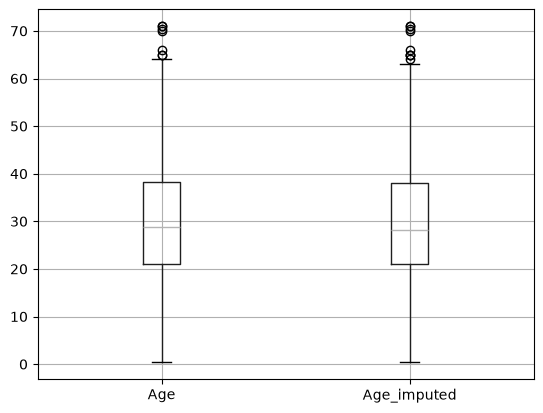

In [60]:
X_train[['Age', 'Age_imputed']].boxplot()

### 💡 Why use `random_state=int(observation['Fare'])` during prediction?

When filling missing ages using random sample imputation (`.sample(1)`), the computer picks a random number every single time you run the code. 

* **The Problem:** If you run your code multiple times on a prediction row, you might get a different random age every time. This makes your model inconsistent and hard to debug!
* **The Solution:** We tie the randomness to something unique about that specific row—like their **Fare** (`observation['Fare']`). 
* **Why it works:** By converting the passenger's Fare into an integer and passing it as the `random_state`, the computer will **always pick the exact same "random" age** for that specific passenger every single time you run the code, keeping your predictions stable and reproducible!

In [64]:
observation = X_train.iloc[0]
sampled_value = X_train['Age'].dropna().sample(1, random_state= int(observation['Fare']))

In [66]:
data = pd.read_csv('house-train.csv', usecols=['GarageQual', 'FireplaceQu', 'SalePrice'])

In [67]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [68]:
data.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [69]:
X = data # we need target column for graph so I did this
y = data['SalePrice']

In [70]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [71]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [72]:
X_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
120,TA,TA,180000,TA,TA
1455,TA,TA,175000,TA,TA
1365,NaN,TA,216000,TA,NaN
762,NaN,TA,215200,TA,NaN
1199,Po,TA,148000,TA,Po


In [87]:
# replace=True lets the computer reuse items so it never runs out of choices.

# GarageQual Imputation
X_train.loc[X_train['GarageQual_imputed'].isnull(), 'GarageQual_imputed'] = X_train['GarageQual'].dropna().sample(X_train['GarageQual_imputed'].isnull().sum(), replace=True).values
X_test.loc[X_test['GarageQual_imputed'].isnull(), 'GarageQual_imputed'] = X_train['GarageQual'].dropna().sample(X_test['GarageQual_imputed'].isnull().sum(), replace=True).values

# FireplaceQu Imputation
X_train.loc[X_train['FireplaceQu_imputed'].isnull(), 'FireplaceQu_imputed'] = X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu_imputed'].isnull().sum(), replace=True).values
X_test.loc[X_test['FireplaceQu_imputed'].isnull(), 'FireplaceQu_imputed'] = X_train['FireplaceQu'].dropna().sample(X_test['FireplaceQu_imputed'].isnull().sum(), replace=True).values

In [101]:
'''X_train['GarageQual'].value_counts() / ...: Calculates the percentage of each category in the original column (ignoring missing values).

X_train['GarageQual_imputed'].value_counts() / ...: Calculates the percentage of each category after you filled in the missing values.'''


temp = pd.concat(
    [
        X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()),
        X_train['GarageQual_imputed'].value_counts() / len(X_train)
    ],
    axis=1)
temp.columns = ['original', 'imputed']

In [102]:
temp

,original,imputed
TA,0.951043,0.952055
Fa,0.037171,0.036815
Gd,0.009973,0.009418
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [103]:
temp = pd.concat(
    [
        X_train['FireplaceQu'].value_counts() / len(X_train['GarageQual'].dropna()),
        X_train['FireplaceQu_imputed'].value_counts() / len(X_train)
    ],
    axis=1)
temp.columns = ['original', 'imputed']

In [105]:
temp # this is red flag

,original,imputed
Gd,0.273799,0.499144
TA,0.228468,0.415240
Fa,0.022665,0.030822
Po,0.015413,0.026541
Ex,0.013599,0.028253


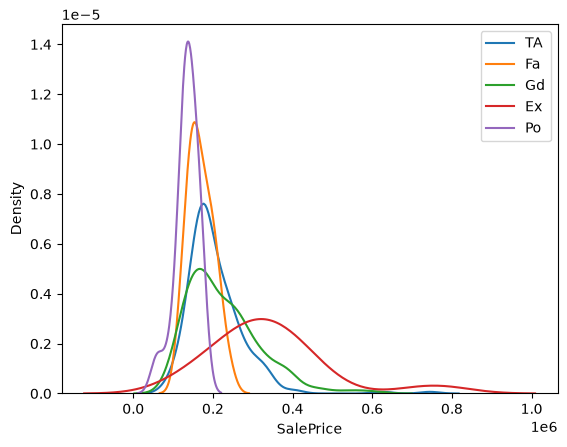

In [108]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.kdeplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'], label=category)

plt.legend()
plt.show()

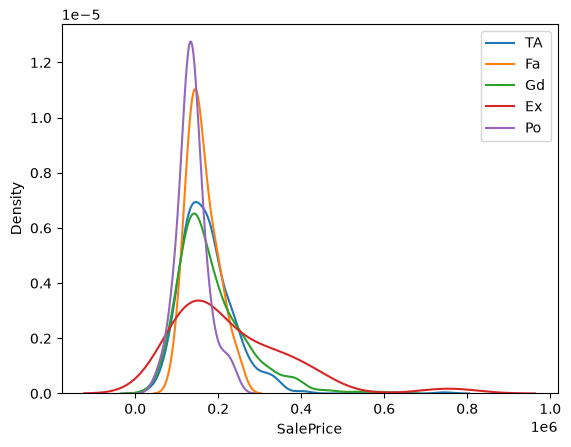

In [109]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.kdeplot(X_train[X_train['FireplaceQu_imputed'] == category]['SalePrice'], label=category)

plt.legend()
plt.show()